In [51]:
library(report)
library(lme4)
library(lmerTest)
library(BayesFactor)
library(bayestestR)
source('bayesMannWhitney.R')
library(ARTool)

# Text Sum

In [52]:
df_q <- read.csv("processed/questionnaires.csv")
# select columns agg_satisfaction, incompletePreference, regret
df_q <- df_q[,c("userID", "domain", "interface", "agg_satisfaction", "incompletePreference", "regret")]
# domain == text
df_q <- df_q[df_q$domain == "text",]
df_q$interface <- factor(df_q$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'))

In [53]:
# H1
df_q_pointwise <- df_q[df_q$interface == 'pointwise',]
df_q_pairwise  <- df_q[df_q$interface == 'pairwise',]
r <- report(wilcox.test(df_q_pointwise$agg_satisfaction, df_q_pairwise$agg_satisfaction)) # Q1-Q4
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$incompletePreference, df_q_pairwise$incompletePreference))  # Q5
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$regret, df_q_pairwise$regret))  # Q6
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$agg_satisfaction and
df_q_pairwise$agg_satisfaction suggests that the effect is negative,
statistically significant, and large (W = 2824.00, p < .001; r (rank biserial)
= -0.30, 95% CI [-0.45, -0.14])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$incompletePreference and
df_q_pairwise$incompletePreference suggests that the effect is negative,
statistically not significant, and tiny (W = 3856.00, p = 0.578; r (rank
biserial) = -0.05, 95% CI [-0.21, 0.12])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$regret and df_q_pairwise$regret suggests that t

  |**************************************************| 100%

[1] 0.2114252

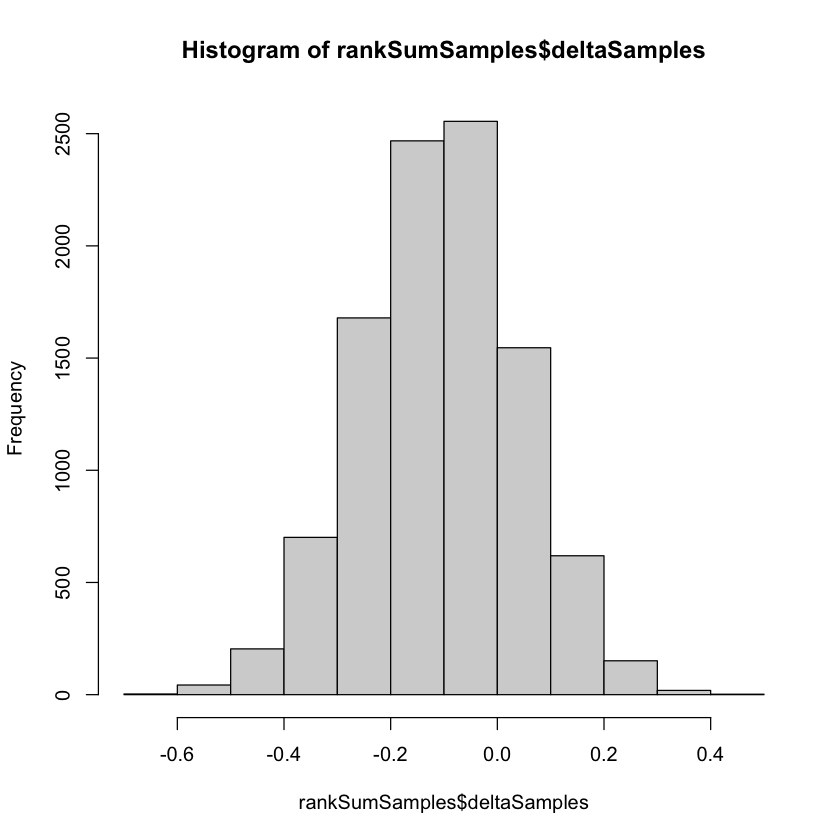

In [54]:
x <- df_q_pointwise$incompletePreference
y <- df_q_pairwise$incompletePreference

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

  |**************************************************| 100%

[1] 0.1909645

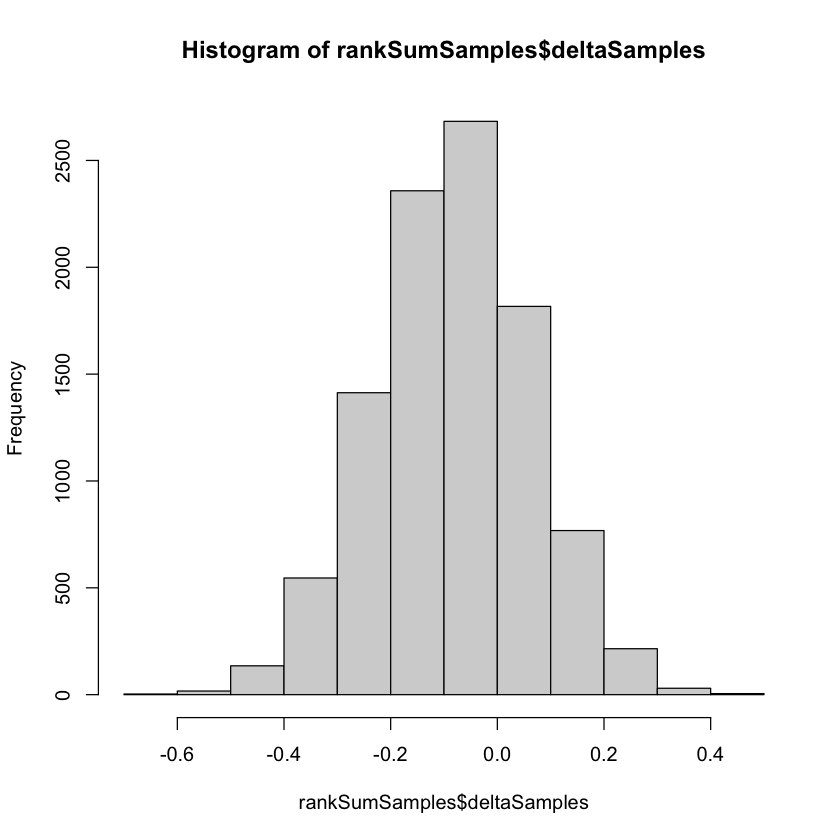

In [55]:
x <- df_q_pointwise$regret
y <- df_q_pairwise$regret

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [56]:
# H2a
df_q_pointwise <- df_q[df_q$interface == 'pointwise',]
df_q_listwise_rating  <- df_q[df_q$interface == 'listwise-rating',]
r <- report(wilcox.test(df_q_pointwise$agg_satisfaction, df_q_listwise_rating$agg_satisfaction))
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$incompletePreference, df_q_listwise_rating$incompletePreference))
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$regret, df_q_listwise_rating$regret))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$agg_satisfaction and
df_q_listwise_rating$agg_satisfaction suggests that the effect is positive,
statistically not significant, and very small (W = 4415.00, p = 0.297; r (rank
biserial) = 0.09, 95% CI [-0.08, 0.25])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$incompletePreference and
df_q_listwise_rating$incompletePreference suggests that the effect is negative,
statistically not significant, and very small (W = 3756.50, p = 0.399; r (rank
biserial) = -0.07, 95% CI [-0.24, 0.10])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$regret and df_q_lis

  |**************************************************| 100%

[1] 0.2768233

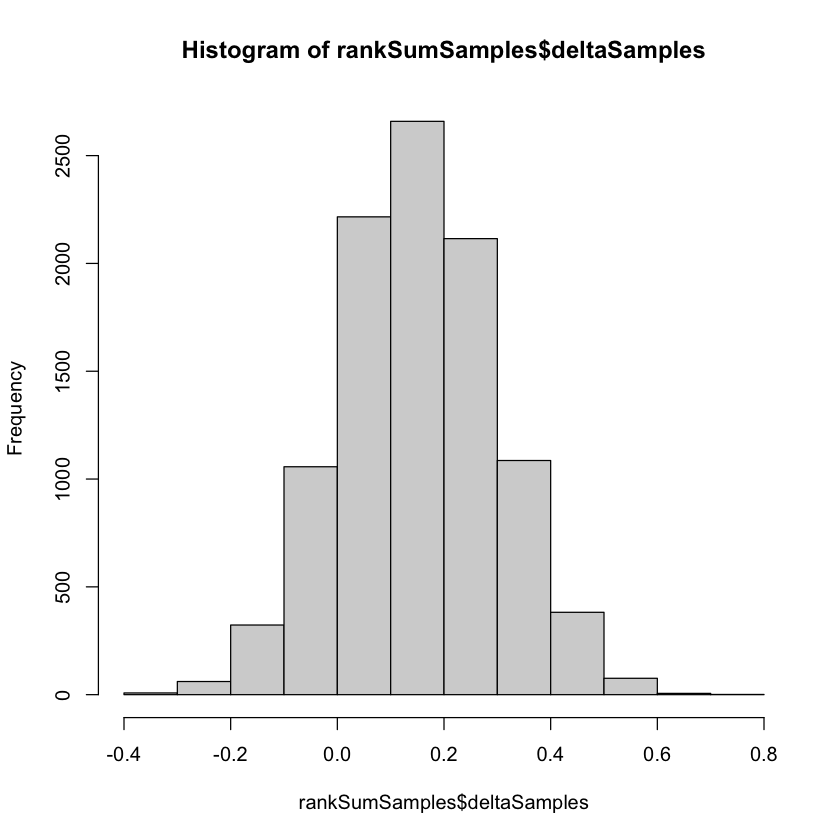

In [57]:
x <- df_q_pointwise$agg_satisfaction
y <- df_q_listwise_rating$agg_satisfaction

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

  |**************************************************| 100%

[1] 0.1936582

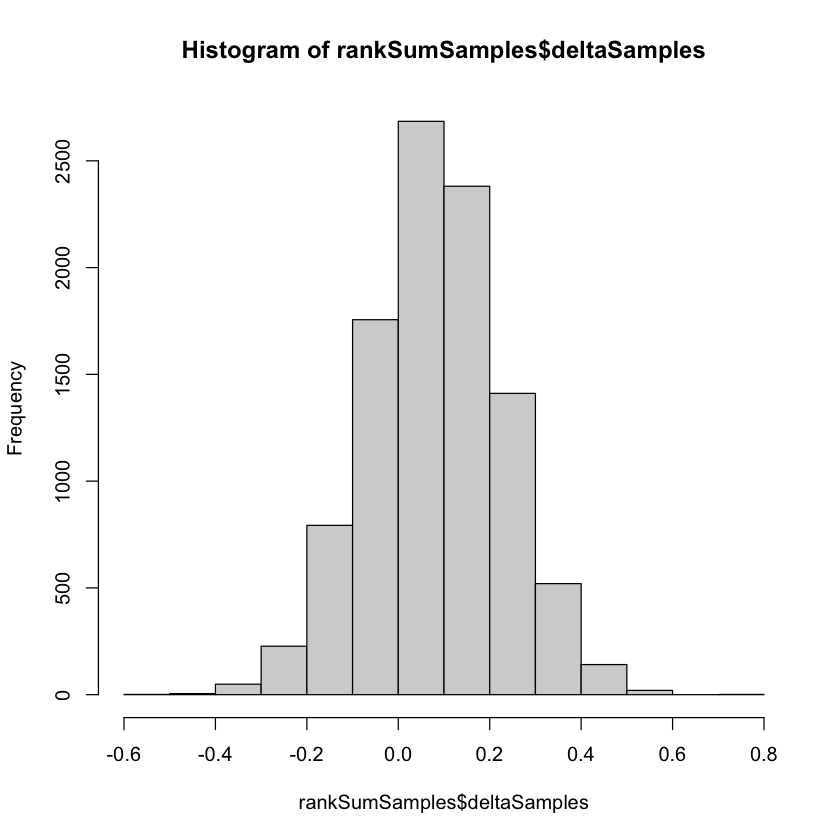

In [58]:
x <- df_q_pointwise$regret
y <- df_q_listwise_rating$regret

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [59]:
# H2b
df_q_pairwise <- df_q[df_q$interface == 'pairwise',]
df_q_listwise_cantie  <- df_q[df_q$interface == 'listwise-cantie',]

r <- report(wilcox.test(df_q_pairwise$agg_satisfaction, df_q_listwise_cantie$agg_satisfaction))
print(r, verbose=TRUE)
r <- report(wilcox.test(df_q_pairwise$incompletePreference, df_q_listwise_cantie$incompletePreference))
print(r, verbose=TRUE)
r <- report(wilcox.test(df_q_pairwise$regret, df_q_listwise_cantie$regret))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pairwise$agg_satisfaction and
df_q_listwise_cantie$agg_satisfaction suggests that the effect is positive,
statistically significant, and large (W = 5285.50, p < .001; r (rank biserial)
= 0.31, 95% CI [0.14, 0.45])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pairwise$incompletePreference and
df_q_listwise_cantie$incompletePreference suggests that the effect is positive,
statistically not significant, and tiny (W = 4063.50, p = 0.970; r (rank
biserial) = 3.33e-03, 95% CI [-0.16, 0.17])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pairwise$regret and df_q_listwise_cantie$regr

  |**************************************************| 100%

[1] 0.1805182

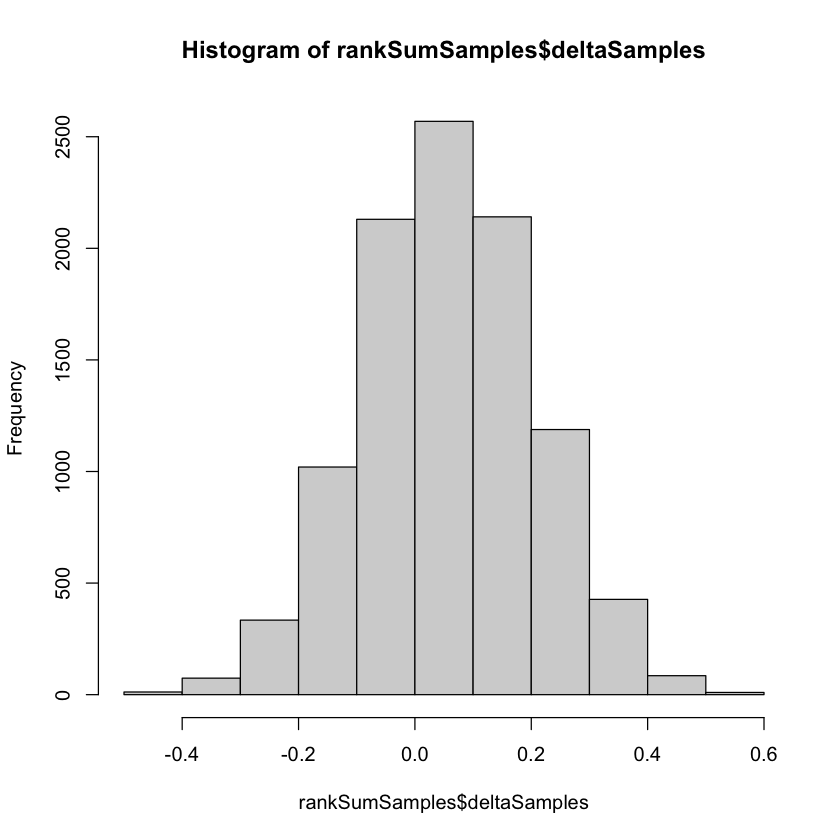

In [60]:
x <- df_q_pairwise$incompletePreference
y <- df_q_listwise_cantie$incompletePreference

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

  |**************************************************| 100%

[1] 0.5186484

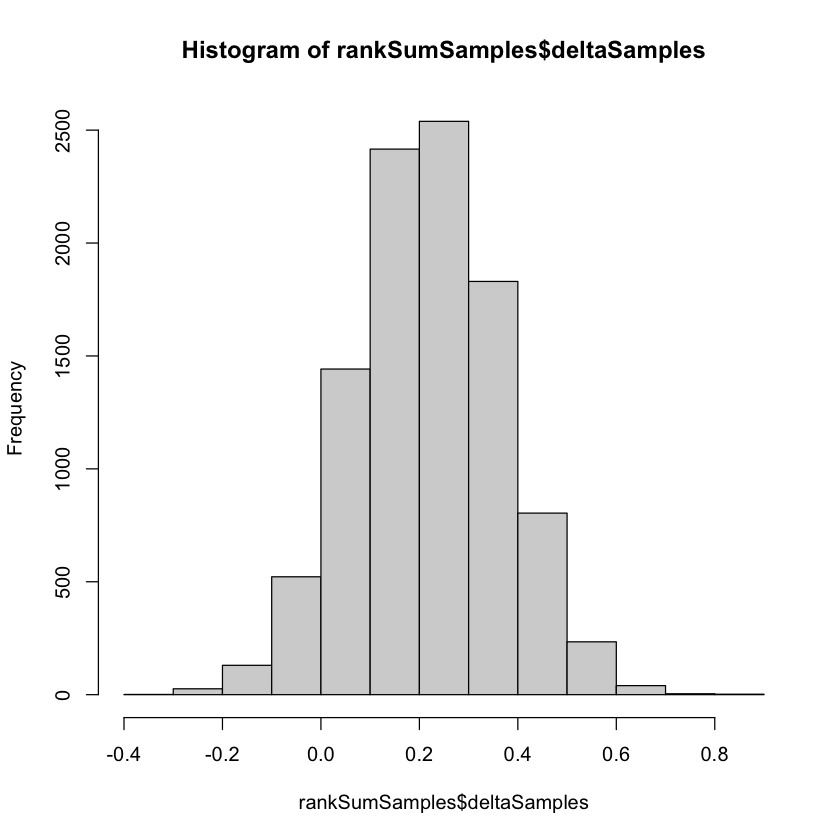

In [61]:
x <- df_q_pairwise$regret
y <- df_q_listwise_cantie$regret

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [62]:
df_h3 <- df_q[df_q$interface != 'pointwise',]
df_h3 <- df_h3[df_h3$interface != 'pairwise',]
df_h3 <- df_h3[df_h3$interface != 'listwise-ranking',]

# H3
df_h3$interface <- factor(df_h3$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
m <- lmer(agg_satisfaction ~ interface + (1|userID), data = df_h3)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: agg_satisfaction ~ interface + (1 | userID)
   Data: df_h3

REML criterion at convergence: 2278.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.4429 -0.4226  0.0887  0.5109  2.4952 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 154.7    12.44   
 Residual             189.1    13.75   
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error     df t value Pr(>|t|)    
(Intercept)                59.306      2.694 87.000  22.015   <2e-16 ***
interfacelistwise-rating   -3.483      3.810 87.000  -0.914    0.363    
interfacelistwise-notie    -1.692      3.810 87.000  -0.444    0.658    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.707              
intrfclstws-n -0.707  0.500       

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict agg_satisfaction with interface
 (formula: agg_satisfaction ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.45) and the part related to the fixed effects
alone (marginal R2) is of 5.87e-03. The model's intercept, corresponding to
interface = listwise-cantie
, is at 59.31 (95% CI [54.00, 64.61], t(265) = 22.02, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -3.48, 95% CI [-10.98, 4.02], t(265) = -0.91, p = 0.361;
Std. beta = -0.19, 95% CI [-0.60, 0.22])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -1.69, 95% CI [-9.19, 5.81], t(265) = -0.44, p = 0.657; Std.
beta = -0.09, 95% CI [-0.50, 0.32])

Standardized parameters were obtained by fitting the model on a stan

In [63]:
df_h3$interface <- factor(df_h3$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
m <- lmer(incompletePreference ~ interface + (1|userID), data = df_h3)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: incompletePreference ~ interface + (1 | userID)
   Data: df_h3

REML criterion at convergence: 2471.4

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.03113 -0.38339  0.00462  0.47018  3.06088 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 490.8    22.15   
 Residual             336.9    18.36   
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error     df t value Pr(>|t|)    
(Intercept)                35.722      4.484 87.000   7.967 5.77e-12 ***
interfacelistwise-rating    1.022      6.341 87.000   0.161    0.872    
interfacelistwise-notie     8.144      6.341 87.000   1.284    0.202    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.707              
intrfclstws-n -0.707  0.500       

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict incompletePreference with interface
 (formula: incompletePreference ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.60) and the part related to the fixed effects
alone (marginal R2) is of 0.02. The model's intercept, corresponding to
interface = listwise-cantie
, is at 35.72 (95% CI [26.89, 44.55], t(265) = 7.97, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 1.02, 95% CI [-11.46, 13.51], t(265) = 0.16, p = 0.872;
Std. beta = 0.04, 95% CI [-0.40, 0.47])
  - The effect of interface [listwise-notie] is statistically non-significant and
positive (beta = 8.14, 95% CI [-4.34, 20.63], t(265) = 1.28, p = 0.200; Std.
beta = 0.28, 95% CI [-0.15, 0.72])

Standardized parameters were obtained by fitting the model on a stand

In [64]:
df_h3$interface <- factor(df_h3$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
m <- lmer(regret ~ interface + (1|userID), data = df_h3)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: regret ~ interface + (1 | userID)
   Data: df_h3

REML criterion at convergence: 2301.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5681 -0.4795  0.1799  0.5129  2.3354 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 258.0    16.06   
 Residual             179.1    13.38   
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error     df t value Pr(>|t|)    
(Intercept)                71.222      3.254 87.000  21.886   <2e-16 ***
interfacelistwise-rating    1.744      4.602 87.000   0.379    0.706    
interfacelistwise-notie     2.200      4.602 87.000   0.478    0.634    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.707              
intrfclstws-n -0.707  0.500       

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict regret with interface
 (formula: regret ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.59) and the part related to the fixed effects
alone (marginal R2) is of 2.06e-03. The model's intercept, corresponding to
interface = listwise-cantie
, is at 71.22 (95% CI [64.81, 77.63], t(265) = 21.89, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 1.74, 95% CI [-7.32, 10.81], t(265) = 0.38, p = 0.705;
Std. beta = 0.08, 95% CI [-0.35, 0.52])
  - The effect of interface [listwise-notie] is statistically non-significant and
positive (beta = 2.20, 95% CI [-6.86, 11.26], t(265) = 0.48, p = 0.633; Std.
beta = 0.11, 95% CI [-0.33, 0.54])

Standardized parameters were obtained by fitting the model on a standardized
version of the d

In [65]:
df_h4 <- df_q[df_q$interface != 'pointwise',]

# H4
df_h4$interface <- factor(df_h4$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
m <- lmer(agg_satisfaction ~ interface + (1|userID), data = df_h4)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: agg_satisfaction ~ interface + (1 | userID)
   Data: df_h4

REML criterion at convergence: 3756.3

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.2302 -0.4148  0.0685  0.5061  2.6686 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 171.3    13.09   
 Residual             161.9    12.73   
Number of obs: 450, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)                64.669      2.740 145.000  23.601   <2e-16 ***
interfacepairwise           4.675      3.875 145.000   1.206   0.2296    
interfacelistwise-rating   -8.847      3.875 145.000  -2.283   0.0239 *  
interfacelistwise-notie    -7.056      3.875 145.000  -1.821   0.0707 .  
interfacelistwise-cantie   -5.364      3.875 145.000  -1.384   0.1684    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict agg_satisfaction with interface
 (formula: agg_satisfaction ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.55) and the part related to the fixed effects
alone (marginal R2) is of 0.07. The model's intercept, corresponding to
interface = listwise-ranking
, is at 64.67 (95% CI [59.28, 70.05], t(443) = 23.60, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically non-significant and
positive (beta = 4.68, 95% CI [-2.94, 12.29], t(443) = 1.21, p = 0.228; Std.
beta = 0.25, 95% CI [-0.16, 0.66])
  - The effect of interface [listwise-rating] is statistically significant and
negative (beta = -8.85, 95% CI [-16.46, -1.23], t(443) = -2.28, p = 0.023; Std.
beta = -0.47, 95% CI [-0.88, -0.07])
  - The effect of interface [listwise-notie] is statistically non-significant and


In [66]:
df_h4$interface <- factor(df_h4$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
m <- lmer(incompletePreference ~ interface + (1|userID), data = df_h4)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: incompletePreference ~ interface + (1 | userID)
   Data: df_h4

REML criterion at convergence: 4106.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.0357 -0.4445 -0.0032  0.5266  3.6076 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 452.5    21.27   
 Residual             334.0    18.27   
Number of obs: 450, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)                38.956      4.335 145.000   8.986 1.26e-15 ***
interfacepairwise          -3.233      6.131 145.000  -0.527    0.599    
interfacelistwise-rating   -2.211      6.131 145.000  -0.361    0.719    
interfacelistwise-notie     4.911      6.131 145.000   0.801    0.424    
interfacelistwise-cantie   -3.233      6.131 145.000  -0.527    0.599    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ 

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict incompletePreference with interface
 (formula: incompletePreference ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.58) and the part related to the fixed effects
alone (marginal R2) is of 0.01. The model's intercept, corresponding to
interface = listwise-ranking
, is at 38.96 (95% CI [30.44, 47.48], t(443) = 8.99, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically non-significant and
negative (beta = -3.23, 95% CI [-15.28, 8.82], t(443) = -0.53, p = 0.598; Std.
beta = -0.12, 95% CI [-0.55, 0.32])
  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -2.21, 95% CI [-14.26, 9.84], t(443) = -0.36, p = 0.719;
Std. beta = -0.08, 95% CI [-0.51, 0.35])
  - The effect of interface [listwise-notie] is statistically non-sign

In [67]:
df_h4$interface <- factor(df_h4$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
m <- lmer(regret ~ interface + (1|userID), data = df_h4)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: regret ~ interface + (1 | userID)
   Data: df_h4

REML criterion at convergence: 3822

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5830 -0.4624  0.1238  0.4968  2.3375 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 230.9    15.19   
 Residual             178.3    13.35   
Number of obs: 450, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error       df t value Pr(>|t|)    
(Intercept)               75.2111     3.1108 145.0000  24.177   <2e-16 ***
interfacepairwise          0.8778     4.3994 145.0000   0.200    0.842    
interfacelistwise-rating  -2.2444     4.3994 145.0000  -0.510    0.611    
interfacelistwise-notie   -1.7889     4.3994 145.0000  -0.407    0.685    
interfacelistwise-cantie  -3.9889     4.3994 145.0000  -0.907    0.366    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Corre

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict regret with interface
 (formula: regret ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.57) and the part related to the fixed effects
alone (marginal R2) is of 7.15e-03. The model's intercept, corresponding to
interface = listwise-ranking
, is at 75.21 (95% CI [69.10, 81.32], t(443) = 24.18, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically non-significant and
positive (beta = 0.88, 95% CI [-7.77, 9.52], t(443) = 0.20, p = 0.842; Std.
beta = 0.04, 95% CI [-0.39, 0.47])
  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -2.24, 95% CI [-10.89, 6.40], t(443) = -0.51, p = 0.610;
Std. beta = -0.11, 95% CI [-0.54, 0.32])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta 

# Image Color Enhancement

In [68]:
df_q <- read.csv("processed/questionnaires.csv")
# select columns agg_satisfaction, incompletePreference, regret
df_q <- df_q[,c("userID", "domain", "interface", "agg_satisfaction", "incompletePreference", "regret")]
# domain == text
df_q <- df_q[df_q$domain == "image",]
df_q$interface <- factor(df_q$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'))

In [69]:
# H1
df_q_pointwise <- df_q[df_q$interface == 'pointwise',]
df_q_pairwise  <- df_q[df_q$interface == 'pairwise',]
r <- report(wilcox.test(df_q_pointwise$agg_satisfaction, df_q_pairwise$agg_satisfaction)) # Q1-Q4
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$incompletePreference, df_q_pairwise$incompletePreference))  # Q5
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$regret, df_q_pairwise$regret))  # Q6
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$agg_satisfaction and
df_q_pairwise$agg_satisfaction suggests that the effect is negative,
statistically not significant, and very small (W = 3652.50, p = 0.256; r (rank
biserial) = -0.10, 95% CI [-0.26, 0.07])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$incompletePreference and
df_q_pairwise$incompletePreference suggests that the effect is negative,
statistically significant, and large (W = 2540.50, p < .001; r (rank biserial)
= -0.37, 95% CI [-0.51, -0.22])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$regret and df_q_pairwise$regret suggests 

  |**************************************************| 100%

[1] 0.2542752

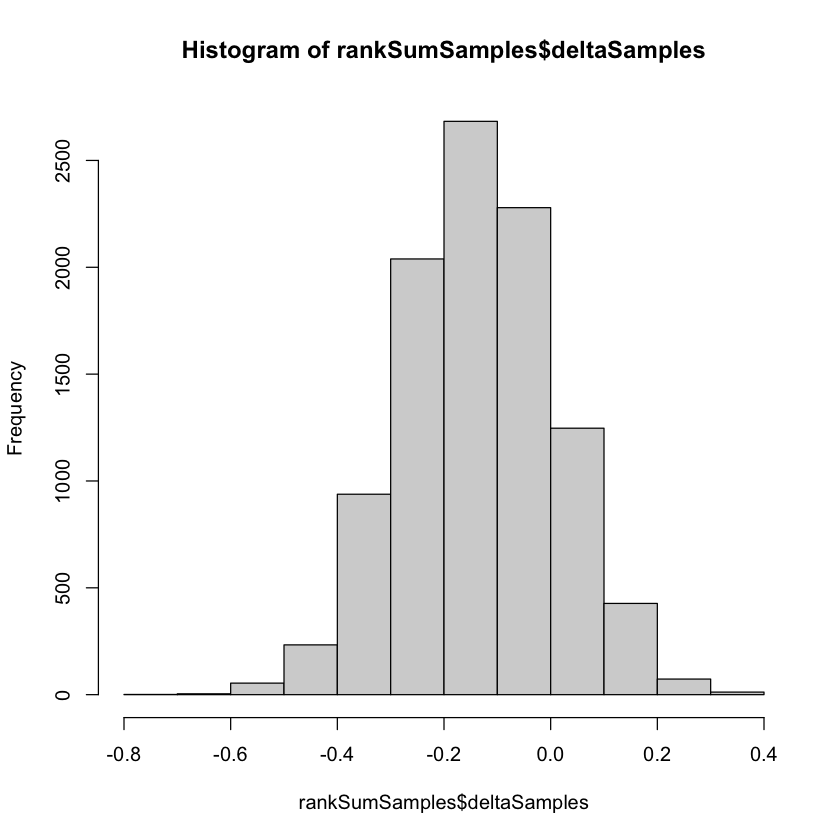

In [70]:
x <- df_q_pointwise$agg_satisfaction
y <- df_q_pairwise$agg_satisfaction

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [71]:
# H2a
df_q_pointwise <- df_q[df_q$interface == 'pointwise',]
df_q_listwise_rating  <- df_q[df_q$interface == 'listwise-rating',]
r <- report(wilcox.test(df_q_pointwise$agg_satisfaction, df_q_listwise_rating$agg_satisfaction))
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$incompletePreference, df_q_listwise_rating$incompletePreference))
print(r, verbose=TRUE)

r <- report(wilcox.test(df_q_pointwise$regret, df_q_listwise_rating$regret))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$agg_satisfaction and
df_q_listwise_rating$agg_satisfaction suggests that the effect is negative,
statistically not significant, and small (W = 3472.00, p = 0.098; r (rank
biserial) = -0.14, 95% CI [-0.30, 0.03])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$incompletePreference and
df_q_listwise_rating$incompletePreference suggests that the effect is negative,
statistically significant, and medium (W = 2994.50, p = 0.002; r (rank
biserial) = -0.26, 95% CI [-0.41, -0.10])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pointwise$regret and df_q_listwise_ratin

  |**************************************************| 100%

[1] 0.6462103

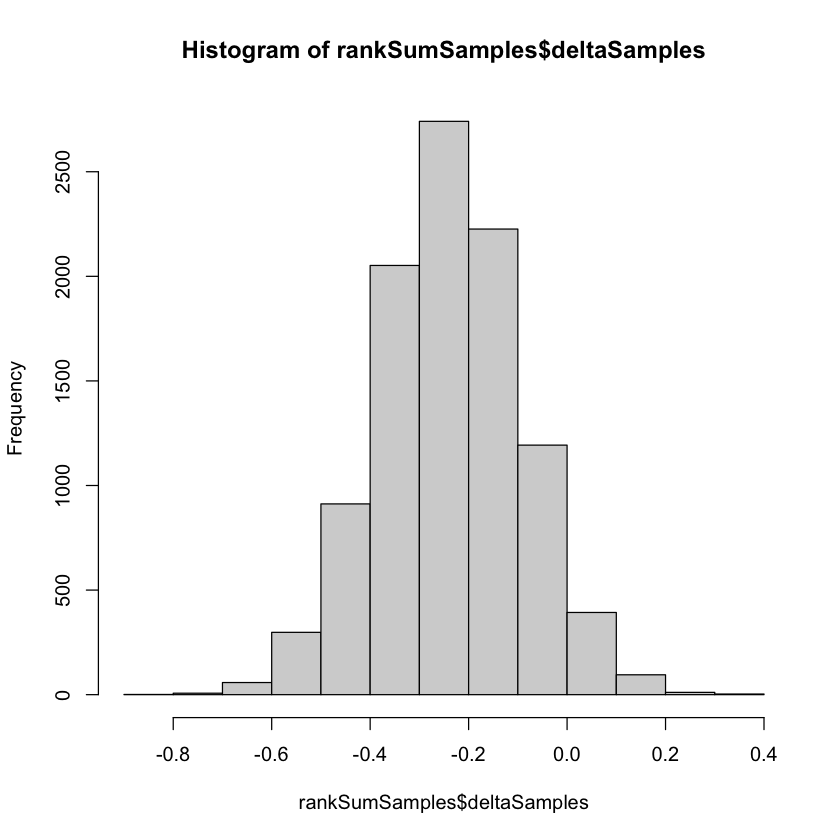

In [72]:
x <- df_q_pointwise$agg_satisfaction
y <- df_q_listwise_rating$agg_satisfaction

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

  |**************************************************| 100%

[1] 0.1840159

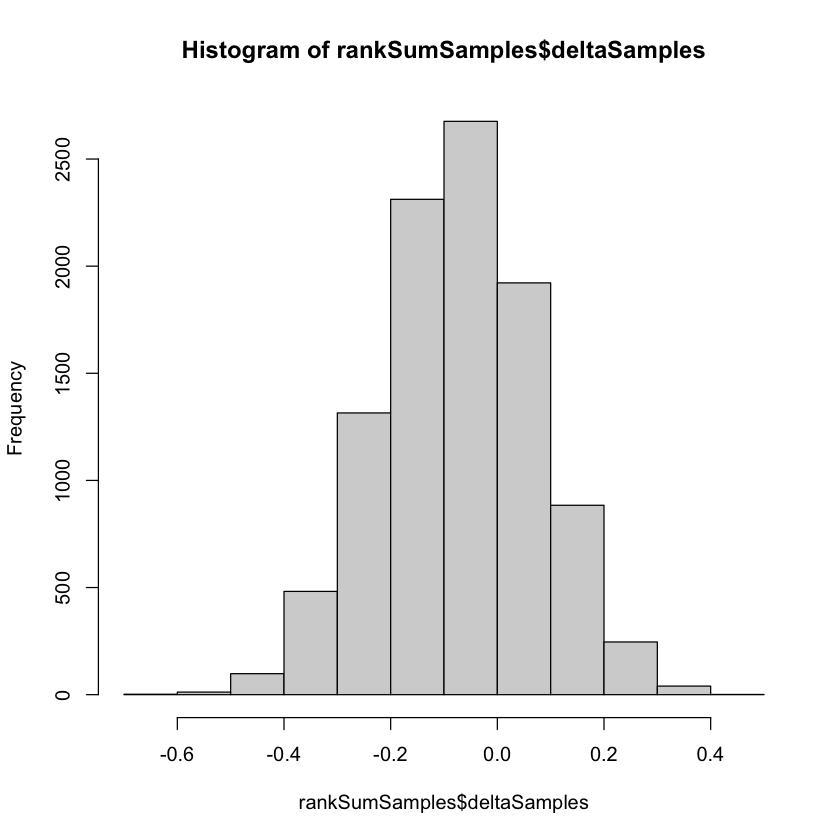

In [73]:
x <- df_q_pointwise$regret
y <- df_q_listwise_rating$regret

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [74]:
# H2b
df_q_pairwise <- df_q[df_q$interface == 'pairwise',]
df_q_listwise_cantie  <- df_q[df_q$interface == 'listwise-cantie',]

r <- report(wilcox.test(df_q_pairwise$agg_satisfaction, df_q_listwise_cantie$agg_satisfaction))
print(r, verbose=TRUE)
r <- report(wilcox.test(df_q_pairwise$incompletePreference, df_q_listwise_cantie$incompletePreference))
print(r, verbose=TRUE)
r <- report(wilcox.test(df_q_pairwise$regret, df_q_listwise_cantie$regret))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pairwise$agg_satisfaction and
df_q_listwise_cantie$agg_satisfaction suggests that the effect is negative,
statistically significant, and small (W = 3288.00, p = 0.029; r (rank biserial)
= -0.19, 95% CI [-0.34, -0.02])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pairwise$incompletePreference and
df_q_listwise_cantie$incompletePreference suggests that the effect is positive,
statistically significant, and medium (W = 4936.00, p = 0.011; r (rank
biserial) = 0.22, 95% CI [0.05, 0.37])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_q_pairwise$regret and df_q_listwise_cantie$regret 

In [75]:
df_h3 <- df_q[df_q$interface != 'pointwise',]
df_h3 <- df_h3[df_h3$interface != 'pairwise',]
df_h3 <- df_h3[df_h3$interface != 'listwise-ranking',]

# H3
df_h3$interface <- factor(df_h3$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
m <- lmer(agg_satisfaction ~ interface + (1|userID), data = df_h3)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: agg_satisfaction ~ interface + (1 | userID)
   Data: df_h3

REML criterion at convergence: 2315.3

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9312 -0.3236  0.0734  0.5033  2.2898 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 153.1    12.37   
 Residual             226.4    15.05   
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error     df t value Pr(>|t|)    
(Intercept)                64.344      2.760 87.000  23.312   <2e-16 ***
interfacelistwise-rating   -3.597      3.903 87.000  -0.922    0.359    
interfacelistwise-notie    -2.722      3.903 87.000  -0.697    0.487    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.707              
intrfclstws-n -0.707  0.500       

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict agg_satisfaction with interface
 (formula: agg_satisfaction ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.41) and the part related to the fixed effects
alone (marginal R2) is of 6.17e-03. The model's intercept, corresponding to
interface = listwise-cantie
, is at 64.34 (95% CI [58.91, 69.78], t(265) = 23.31, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -3.60, 95% CI [-11.28, 4.09], t(265) = -0.92, p = 0.358;
Std. beta = -0.19, 95% CI [-0.58, 0.21])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -2.72, 95% CI [-10.41, 4.96], t(265) = -0.70, p = 0.486; Std.
beta = -0.14, 95% CI [-0.54, 0.26])

Standardized parameters were obtained by fitting the model on a sta

In [76]:
df_h3$interface <- factor(df_h3$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
m <- lmer(incompletePreference ~ interface + (1|userID), data = df_h3)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: incompletePreference ~ interface + (1 | userID)
   Data: df_h3

REML criterion at convergence: 2430.3

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.12217 -0.44644  0.08264  0.37612  2.55112 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 391.2    19.78   
 Residual             296.6    17.22   
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error     df t value Pr(>|t|)    
(Intercept)                36.189      4.042 87.000   8.954 5.58e-14 ***
interfacelistwise-rating    5.144      5.716 87.000   0.900    0.371    
interfacelistwise-notie     6.756      5.716 87.000   1.182    0.240    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.707              
intrfclstws-n -0.707  0.500       

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict incompletePreference with interface
 (formula: incompletePreference ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.57) and the part related to the fixed effects
alone (marginal R2) is of 0.01. The model's intercept, corresponding to
interface = listwise-cantie
, is at 36.19 (95% CI [28.23, 44.15], t(265) = 8.95, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 5.14, 95% CI [-6.11, 16.40], t(265) = 0.90, p = 0.369;
Std. beta = 0.20, 95% CI [-0.23, 0.63])
  - The effect of interface [listwise-notie] is statistically non-significant and
positive (beta = 6.76, 95% CI [-4.50, 18.01], t(265) = 1.18, p = 0.238; Std.
beta = 0.26, 95% CI [-0.17, 0.69])

Standardized parameters were obtained by fitting the model on a standa

In [77]:
df_h3$interface <- factor(df_h3$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
m <- lmer(regret ~ interface + (1|userID), data = df_h3)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: regret ~ interface + (1 | userID)
   Data: df_h3

REML criterion at convergence: 2278.4

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.4148 -0.4868  0.1370  0.4463  3.1248 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 174.5    13.21   
 Residual             181.9    13.49   
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)               78.8222     2.7993 87.0000  28.158   <2e-16 ***
interfacelistwise-rating   0.6778     3.9588 87.0000   0.171    0.864    
interfacelistwise-notie   -2.0778     3.9588 87.0000  -0.525    0.601    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.707              
intrfclstws-n -0.707  0.500       

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict regret with interface
 (formula: regret ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.49) and the part related to the fixed effects
alone (marginal R2) is of 3.86e-03. The model's intercept, corresponding to
interface = listwise-cantie
, is at 78.82 (95% CI [73.31, 84.33], t(265) = 28.16, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 0.68, 95% CI [-7.12, 8.47], t(265) = 0.17, p = 0.864; Std.
beta = 0.04, 95% CI [-0.38, 0.45])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -2.08, 95% CI [-9.87, 5.72], t(265) = -0.52, p = 0.600; Std.
beta = -0.11, 95% CI [-0.53, 0.31])

Standardized parameters were obtained by fitting the model on a standardized
version of the 

In [78]:
df_h4 <- df_q[df_q$interface != 'pointwise',]

# H4
df_h4$interface <- factor(df_h4$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
m <- lmer(agg_satisfaction ~ interface + (1|userID), data = df_h4)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: agg_satisfaction ~ interface + (1 | userID)
   Data: df_h4

REML criterion at convergence: 3905.2

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.6768 -0.3736  0.1104  0.5336  2.6499 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 145.6    12.07   
 Residual             261.8    16.18   
Number of obs: 450, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error       df t value Pr(>|t|)    
(Intercept)               60.0611     2.7860 145.0000  21.558   <2e-16 ***
interfacepairwise         -1.8944     3.9400 145.0000  -0.481    0.631    
interfacelistwise-rating   0.6861     3.9400 145.0000   0.174    0.862    
interfacelistwise-notie    1.5611     3.9400 145.0000   0.396    0.693    
interfacelistwise-cantie   4.2833     3.9400 145.0000   1.087    0.279    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict agg_satisfaction with interface
 (formula: agg_satisfaction ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.36) and the part related to the fixed effects
alone (marginal R2) is of 0.01. The model's intercept, corresponding to
interface = listwise-ranking
, is at 60.06 (95% CI [54.59, 65.54], t(443) = 21.56, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically non-significant and
negative (beta = -1.89, 95% CI [-9.64, 5.85], t(443) = -0.48, p = 0.631; Std.
beta = -0.09, 95% CI [-0.48, 0.29])
  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 0.69, 95% CI [-7.06, 8.43], t(443) = 0.17, p = 0.862; Std.
beta = 0.03, 95% CI [-0.35, 0.42])
  - The effect of interface [listwise-notie] is statistically non-significant and


In [79]:
df_h4$interface <- factor(df_h4$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
m <- lmer(incompletePreference ~ interface + (1|userID), data = df_h4)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: incompletePreference ~ interface + (1 | userID)
   Data: df_h4

REML criterion at convergence: 4031.1

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.1671 -0.4451  0.0393  0.3525  2.7296 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 363.4    19.06   
 Residual             286.8    16.94   
Number of obs: 450, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)                21.900      3.912 145.000   5.599 1.05e-07 ***
interfacepairwise          24.644      5.532 145.000   4.455 1.67e-05 ***
interfacelistwise-rating   19.433      5.532 145.000   3.513 0.000591 ***
interfacelistwise-notie    21.044      5.532 145.000   3.804 0.000209 ***
interfacelistwise-cantie   14.289      5.532 145.000   2.583 0.010786 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ 

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict incompletePreference with interface
 (formula: incompletePreference ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.60) and the part related to the fixed effects
alone (marginal R2) is of 0.10. The model's intercept, corresponding to
interface = listwise-ranking
, is at 21.90 (95% CI [14.21, 29.59], t(443) = 5.60, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically significant and positive
(beta = 24.64, 95% CI [13.77, 35.52], t(443) = 4.45, p < .001; Std. beta =
0.92, 95% CI [0.52, 1.33])
  - The effect of interface [listwise-rating] is statistically significant and
positive (beta = 19.43, 95% CI [8.56, 30.31], t(443) = 3.51, p < .001; Std.
beta = 0.73, 95% CI [0.32, 1.14])
  - The effect of interface [listwise-notie] is statistically significant and
positive 

In [80]:
df_h4$interface <- factor(df_h4$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
m <- lmer(regret ~ interface + (1|userID), data = df_h4)
summary(m)
print(report(m), verbose=TRUE)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: regret ~ interface + (1 | userID)
   Data: df_h4

REML criterion at convergence: 3770.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5165 -0.5034  0.1260  0.5001  3.2271 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 165.4    12.86   
 Residual             171.0    13.08   
Number of obs: 450, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)                82.800      2.723 145.000  30.408  < 2e-16 ***
interfacepairwise         -13.933      3.851 145.000  -3.618 0.000409 ***
interfacelistwise-rating   -3.300      3.851 145.000  -0.857 0.392885    
interfacelistwise-notie    -6.056      3.851 145.000  -1.573 0.118009    
interfacelistwise-cantie   -3.978      3.851 145.000  -1.033 0.303342    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlati

We fitted a linear mixed model (estimated using REML and nloptwrap optimizer)
to predict regret with interface
 (formula: regret ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.52) and the part related to the fixed effects
alone (marginal R2) is of 0.06. The model's intercept, corresponding to
interface = listwise-ranking
, is at 82.80 (95% CI [77.45, 88.15], t(443) = 30.41, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically significant and negative
(beta = -13.93, 95% CI [-21.50, -6.37], t(443) = -3.62, p < .001; Std. beta =
-0.74, 95% CI [-1.15, -0.34])
  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -3.30, 95% CI [-10.87, 4.27], t(443) = -0.86, p = 0.392;
Std. beta = -0.18, 95% CI [-0.58, 0.23])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = 